<a href="https://colab.research.google.com/github/saopa28/INSE-6450/blob/main/Milestone%203/Monitoring_Adaptation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Setup, configuration, and versioned settings

In [2]:
import os, gc, json, time, hashlib, resource, subprocess, numpy as np, pandas as pd, xgboost as xgb, psutil
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

pd.set_option("display.float_format", "{:.6f}".format)
DATA_PATH = "https://github.com/saopa28/INSE-6450/releases/download/v1.0-engineered/criteo_uplift_engineered.zip"
TARGET, SEED = "conversion", 42
RAW = [f"f{i}" for i in range(12)]
FEATS = RAW + ["f4_x_f9", "f4_x_f11", "f9_x_f11", "f4_squared", "f9_squared", "f11_squared"]
CRITICAL = ["f4", "f9", "f11"]                       # stricter null threshold (0.1%) per Bella's Section 3.1
OUT = "/content/milestone3_outputs"; os.makedirs(OUT, exist_ok=True)

# Same config as the Milestone 2 selected tuning run ("5. learning_rate 0.05 -> 0.1", trees 244/55/84/19).
CLF = dict(n_estimators=1000, learning_rate=0.05, max_depth=6, min_child_weight=5, subsample=0.8,
           colsample_bytree=0.8, tree_method="hist", eval_metric="logloss", early_stopping_rounds=30,
           n_jobs=-1, random_state=SEED)
REG = dict(n_estimators=1000, learning_rate=0.05, max_depth=4, min_child_weight=50, subsample=0.8,
           colsample_bytree=0.8, reg_lambda=5.0, tree_method="hist", early_stopping_rounds=30,
           n_jobs=-1, random_state=SEED)
CLF_BEST, REG_BEST = {**CLF, "learning_rate": 0.1}, {**REG, "learning_rate": 0.1}

# 2. Metric functions (copied from Milestone 2)

In [3]:
def gain_curve(y, t, s, auuc=False):
    o = np.argsort(-s, kind="stable"); y, t = y[o], t[o]
    nt, nc, yt, yc = np.cumsum(t), np.cumsum(1 - t), np.cumsum(y * t), np.cumsum(y * (1 - t))
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.nan_to_num(yt / nt - yc / nc) * (nt + nc) if auuc else yt - yc * np.where(nc > 0, nt / nc, 0)

def qini(y, t, s, auuc=False):
    q = gain_curve(y, t, s, auuc); n = len(q)
    return float(np.mean(q - np.linspace(q[-1] / n, q[-1], n)) / n)

def uplift_at(y, t, s, k):
    top = np.argsort(-s, kind="stable")[: int(len(s) * k)]
    return float(y[top][t[top] == 1].mean() - y[top][t[top] == 0].mean())

def boot_ci(y, t, s, n=100):
    rng, vals = np.random.default_rng(SEED), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); vals.append(qini(y[i], t[i], s[i]))
    return np.percentile(vals, [2.5, 97.5])

# 3. X-learner (copied from Milestone 2, generalised to take its own training arrays)

In [4]:
def fit_xlearner(X, t, y, Xv, tv, yv, clf=CLF_BEST, reg=REG_BEST):
    T, C, Tv, Cv = t == 1, t == 0, tv == 1, tv == 0
    mu1 = xgb.XGBClassifier(**clf).fit(X[T], y[T], eval_set=[(Xv[Tv], yv[Tv])], verbose=False)
    mu0 = xgb.XGBClassifier(**clf).fit(X[C], y[C], eval_set=[(Xv[Cv], yv[Cv])], verbose=False)
    D1, D1v = y[T] - mu0.predict_proba(X[T])[:, 1], yv[Tv] - mu0.predict_proba(Xv[Tv])[:, 1]
    D0, D0v = mu1.predict_proba(X[C])[:, 1] - y[C], mu1.predict_proba(Xv[Cv])[:, 1] - yv[Cv]
    tau1 = xgb.XGBRegressor(**reg).fit(X[T], D1, eval_set=[(Xv[Tv], D1v)], verbose=False)
    tau0 = xgb.XGBRegressor(**reg).fit(X[C], D0, eval_set=[(Xv[Cv], D0v)], verbose=False)
    return dict(mu1=mu1, mu0=mu0, tau1=tau1, tau0=tau0, g=float(t.mean()))

def pred_x(m, X):
    # Scoring uses only the two Stage 2 models (tau0, tau1); mu0/mu1 are not called at inference.
    return m["g"] * m["tau0"].predict(X) + (1 - m["g"]) * m["tau1"].predict(X)

def size_mb(*ms):
    return sum(len(m.get_booster().save_raw(raw_format="ubj")) for m in ms) / 1e6

# 4. Load data and create the same 70/15/15 stratified split as Milestone 2

In [5]:
cols = FEATS + ["treatment", TARGET, "visit"]
df = pd.concat(pd.read_csv(DATA_PATH, compression="zip", usecols=cols,
                           dtype={c: "float32" for c in FEATS}, chunksize=1_000_000), ignore_index=True)
strata = lambda d: d.treatment.astype(int) * 2 + d[TARGET].astype(int)
tr, rest = train_test_split(df, test_size=0.30, stratify=strata(df), random_state=SEED)
va, te = train_test_split(rest, test_size=0.50, stratify=strata(rest), random_state=SEED)
arr = lambda d: (d[FEATS].to_numpy(np.float32), d.treatment.to_numpy(np.int8), d[TARGET].to_numpy(np.int8))
(Xtr, ttr, ytr), (Xva, tva, yva), (Xte, tte, yte) = arr(tr), arr(va), arr(te)
DATA_SNAPSHOT = hashlib.sha256(f"{len(df)}|{SEED}|{FEATS}".encode()).hexdigest()[:12]
del df, tr, va, rest; gc.collect()
print(f"train={len(ytr):,} val={len(yva):,} test={len(yte):,} | snapshot={DATA_SNAPSHOT}")

train=9,785,714 val=2,096,939 test=2,096,939 | snapshot=b03e3445379a


# 5. Model v1 (baseline, trained on the original period) and its versioned manifest - Section 4.2

In [6]:
# Download the saved Milestone 2 X-learner from the GitHub repo and load it; train from scratch only if that fails.
MODEL_URL = "https://raw.githubusercontent.com/saopa28/INSE-6450/main/Milestone%203/xlearner_model"
MODEL_DIR = "/content/xlearner_model"; os.makedirs(MODEL_DIR, exist_ok=True)
PARTS = [("mu1", xgb.XGBClassifier), ("mu0", xgb.XGBClassifier), ("tau1", xgb.XGBRegressor), ("tau0", xgb.XGBRegressor)]
try:
    import urllib.request
    for name in ["mu1", "mu0", "tau1", "tau0", "metadata"]:
        urllib.request.urlretrieve(f"{MODEL_URL}/{name}.json", f"{MODEL_DIR}/{name}.json")
    meta = json.load(open(f"{MODEL_DIR}/metadata.json"))
    v1 = {}
    for k, cls in PARTS:
        est = cls(); est.load_model(f"{MODEL_DIR}/{k}.json"); v1[k] = est
    v1["g"] = float(meta["g"])
    v1_train_s = float(meta["training_s"])   # training time recorded when the model was saved
    print(f"Loaded Milestone 2 model from GitHub | run: {meta['selected_run']} | g = {v1['g']:.4f} | "
          f"saved with xgboost {meta['xgboost_version']}, running {xgb.__version__}")
except Exception as e:
    print("Could not load the saved model (", e, ") - training the Milestone 2 configuration from scratch")
    t0 = time.perf_counter(); v1 = fit_xlearner(Xtr, ttr, ytr, Xva, tva, yva); v1_train_s = time.perf_counter() - t0

def git_commit():
    try:
        return subprocess.check_output(["git", "-C", "/home/claude/inse-6450", "rev-parse", "--short", "HEAD"],
                                       text=True, stderr=subprocess.DEVNULL).strip()
    except Exception:
        return "unknown (set manually)"

def save_version(name, model, metrics, train_s, parent=None):
    d = f"{OUT}/{name}"; os.makedirs(d, exist_ok=True)
    artifacts = {}
    for k in ["mu1", "mu0", "tau1", "tau0"]:
        raw = model[k].get_booster().save_raw(raw_format="ubj")
        path = f"{d}/{k}.ubj"; open(path, "wb").write(raw)
        artifacts[k] = hashlib.sha256(raw).hexdigest()[:16]
    manifest = dict(version=name, parent=parent, created=time.strftime("%Y-%m-%d %H:%M:%S"),
                    code_commit=git_commit(), data_snapshot=DATA_SNAPSHOT, seed=SEED,
                    features=FEATS, clf=CLF_BEST, reg=REG_BEST, g=model["g"],
                    train_seconds=round(train_s, 1), artifact_sha256=artifacts, metrics=metrics)
    json.dump(manifest, open(f"{d}/manifest.json", "w"), indent=2, default=str)
    return manifest

v1_manifest = save_version("v1", v1, {"test_qini": qini(yte, tte, pred_x(v1, Xte))}, v1_train_s)
print(json.dumps(v1_manifest, indent=2, default=str)[:800])
# Should print 244/55/84/19, the Milestone 2 tree counts. If it does not, v1 is not the Milestone 2 model.
def n_trees(m):
    try: return m.best_iteration + 1
    except Exception: return m.get_booster().num_boosted_rounds()
print("Trees (mu1/mu0/tau1/tau0):", "/".join(str(n_trees(v1[k])) for k in ["mu1", "mu0", "tau1", "tau0"]))
print("Test Qini of v1:", round(qini(yte, tte, pred_x(v1, Xte)), 6), "(Milestone 2 reported 0.000376)")

Loaded Milestone 2 model from GitHub | run: 5. learning_rate 0.05 -> 0.1 | g = 0.8500 | saved with xgboost 3.4.1, running 3.4.1
{
  "version": "v1",
  "parent": null,
  "created": "2026-11-15 00:07:54",
  "code_commit": "unknown (set manually)",
  "data_snapshot": "b03e3445379a",
  "seed": 42,
  "features": [
    "f0",
    "f1",
    "f2",
    "f3",
    "f4",
    "f5",
    "f6",
    "f7",
    "f8",
    "f9",
    "f10",
    "f11",
    "f4_x_f9",
    "f4_x_f11",
    "f9_x_f11",
    "f4_squared",
    "f9_squared",
    "f11_squared"
  ],
  "clf": {
    "n_estimators": 1000,
    "learning_rate": 0.1,
    "max_depth": 6,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "eval_metric": "logloss",
    "early_stopping_rounds": 30,
    "n_jobs": -1,
    "random_state": 42
  },
  "reg": {
    "n_estimators": 1000,
    "learning_rate": 0.1,
    "max_depth": 4,
    "min_
Trees (mu1/mu0/tau1/tau0): 244/55/84/19
Test Qini of v1: 0.000376 (Mile

In [7]:
# Section 1 - share of users with negative predicted uplift ("sleeping dogs"), Milestone 2 model
s = pred_x(v1, Xte); neg = s < 0
print(f"negative predicted uplift: {neg.mean():.2%} of test users")
print("actual uplift in that group:", yte[neg][tte[neg] == 1].mean() - yte[neg][tte[neg] == 0].mean())

negative predicted uplift: 0.04% of test users
actual uplift in that group: 0.019822095321765876


# 6. Section 3.3 - Simulated production stream with injected drift and the Monitoring Dashboard

,day,n,psi_max,psi_max_feat,psi_score,null_max,oor_rate,qini,uplift10,alerts,qini_alert
0,0,174745,0.012906,f9_squared,0.001072,0.000000,0.000000,0.000352,0.007704,OK,
1,1,174745,0.014142,f9_squared,0.001100,0.000000,0.000006,0.000417,0.009589,OK,
2,2,174745,0.013672,f9_squared,0.001093,0.000000,0.000000,0.000477,0.008889,OK,
3,3,174745,0.013314,f9_squared,0.001298,0.000000,0.000000,0.000266,0.005531,OK,
4,4,174745,13.271330,f9_x_f11,9.964865,0.000000,0.000000,0.000265,0.006158,BLOCK: PSI>=0.25,
5,5,174745,13.272846,f9_x_f11,9.746459,0.000000,0.000006,0.000348,0.007407,BLOCK: PSI>=0.25,
6,6,174745,13.273853,f9_x_f11,8.693252,0.000000,0.000006,0.000341,0.006577,BLOCK: PSI>=0.25,
7,7,174745,0.013734,f9_squared,0.788786,0.097811,0.000000,0.000415,0.010609,BLOCK: null rate,
8,8,174745,9.056162,f2,0.014552,0.000000,0.901445,0.000345,0.009200,BLOCK: PSI>=0.25; BLOCK: out-of-range rows >1%,
9,9,174745,9.048576,f2,0.014085,0.000000,0.900730,0.000255,0.004800,BLOCK: PSI>=0.25; BLOCK: out-of-range rows >1%,


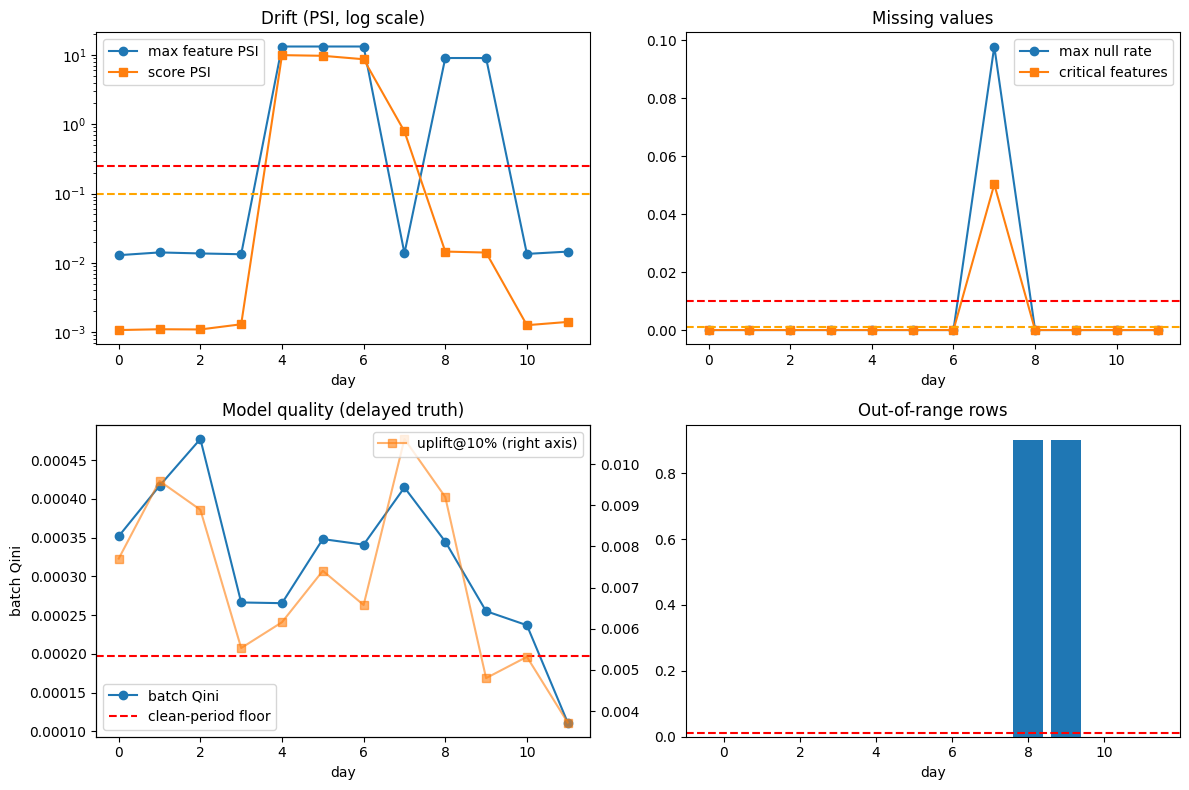

In [12]:
# The test split is cut into 12 "daily" batches. Days 0-3 are clean; drift is injected on later days.
# Labels in each batch act as the delayed truth (Section 3.2 holdout proxy).
N_DAYS = 12
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(yte))
batches = np.array_split(perm, N_DAYS)
ref_sd = Xtr.std(axis=0); ref_min, ref_max = Xtr.min(axis=0), Xtr.max(axis=0)
f = {n: i for i, n in enumerate(FEATS)}

def psi(ref, cur, bins=10):
    cur = cur[~np.isnan(cur)]
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, edges)[0] / len(ref), 1e-6, None)
    c = np.clip(np.histogram(cur, edges)[0] / max(len(cur), 1), 1e-6, None)
    return float(np.sum((c - r) * np.log(c / r)))

def kl_js(ref, cur, bins=10):
    cur = cur[~np.isnan(cur)]
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    p = np.clip(np.histogram(ref, edges)[0] / len(ref), 1e-9, None)
    q = np.clip(np.histogram(cur, edges)[0] / max(len(cur), 1), 1e-9, None)
    m = 0.5 * (p + q)
    kl = float(np.sum(p * np.log(p / q))); js = float(0.5 * np.sum(p * np.log(p / m)) + 0.5 * np.sum(q * np.log(q / m)))
    return kl, js

def rebuild(X):
    """Recompute the six engineered features from the raw columns, so drift in f4/f9/f11 is consistent."""
    f4, f9, f11 = X[:, f["f4"]], X[:, f["f9"]], X[:, f["f11"]]
    X[:, f["f4_x_f9"]], X[:, f["f4_x_f11"]], X[:, f["f9_x_f11"]] = f4 * f9, f4 * f11, f9 * f11
    X[:, f["f4_squared"]], X[:, f["f9_squared"]], X[:, f["f11_squared"]] = f4 ** 2, f9 ** 2, f11 ** 2
    return X

def inject_drift(day, X, t, y):
    X, t, y = X.copy(), t.copy(), y.copy()
    if 4 <= day <= 6:                       # covariate shift on f9: +0.5 sigma
        X[:, f["f9"]] += 0.5 * ref_sd[f["f9"]]
    if day == 7:                            # missing values on critical features (5%)
        for c in CRITICAL:
            X[rng.random(len(X)) < 0.05, f[c]] = np.nan
    if day in (8, 9):                       # covariate shift on f0..f3: +1 sigma
        for c in ["f0", "f1", "f2", "f3"]:
            X[:, f[c]] += ref_sd[f[c]]
    if day in (10, 11):                     # concept drift: 30% of treatment labels scrambled (attenuated uplift)
        idx = rng.random(len(t)) < 0.30
        t[idx] = rng.integers(0, 2, idx.sum())
    return rebuild(X), t, y

rows, shown = [], None
for day, idx in enumerate(batches):
    Xb, tb, yb = inject_drift(day, Xte[idx], tte[idx], yte[idx])
    nan_mask = np.isnan(Xb).any(axis=1)
    s = pred_x(v1, np.nan_to_num(Xb, nan=0.0))
    s[nan_mask] = 0.0                       # runtime guard: rows with NaN are not targeted (score 0)

    psis = {c: psi(Xtr[:, f[c]], Xb[:, f[c]]) for c in FEATS}
    nulls = {c: float(np.isnan(Xb[:, f[c]]).mean()) for c in FEATS}
    oor_row = ((Xb < ref_min) | (Xb > ref_max)).any(axis=1).mean()
    rec = dict(day=day, n=len(idx),
               psi_max=max(psis.values()), psi_max_feat=max(psis, key=psis.get),
               psi_score=psi(v1_train_scores := pred_x(v1, Xtr[:20000]), s),
               null_max_critical=max(nulls[c] for c in CRITICAL), null_max=max(nulls.values()),
               oor_rate=float(oor_row), qini=qini(yb, tb, s), uplift10=uplift_at(yb, tb, s, 0.1),
               pred_uplift_mean=float(s.mean()), actual_uplift=float(yb[tb == 1].mean() - yb[tb == 0].mean()))
    alerts = []
    if rec["psi_max"] >= 0.25: alerts.append("BLOCK: PSI>=0.25")
    elif rec["psi_max"] >= 0.10: alerts.append("WARN: PSI 0.1-0.25")
    if rec["null_max"] > 0.01 or rec["null_max_critical"] > 0.001: alerts.append("BLOCK: null rate")
    if rec["oor_rate"] > 0.01: alerts.append("BLOCK: out-of-range rows >1%")
    rec["alerts"] = "; ".join(alerts) or "OK"
    rows.append(rec)

log = pd.DataFrame(rows)
log.to_csv(f"{OUT}/monitoring_log.csv", index=False)
baseline = log[log.day <= 3]
qini_floor = baseline.qini.mean() - 2 * baseline.qini.std()
log["qini_alert"] = np.where(log.qini < qini_floor, "ALERT: Qini below clean-period band", "")
display(log[["day", "n", "psi_max", "psi_max_feat", "psi_score", "null_max", "oor_rate", "qini", "uplift10", "alerts", "qini_alert"]])

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax[0, 0].plot(log.day, log.psi_max, "o-", label="max feature PSI"); ax[0, 0].plot(log.day, log.psi_score, "s-", label="score PSI")
ax[0, 0].axhline(0.1, c="orange", ls="--"); ax[0, 0].axhline(0.25, c="red", ls="--"); ax[0, 0].set(title="Drift (PSI, log scale)", xlabel="day", yscale="log"); ax[0, 0].legend()
ax[0, 1].plot(log.day, log.null_max, "o-", label="max null rate"); ax[0, 1].plot(log.day, log.null_max_critical, "s-", label="critical features")
ax[0, 1].axhline(0.01, c="red", ls="--"); ax[0, 1].axhline(0.001, c="orange", ls="--"); ax[0, 1].set(title="Missing values", xlabel="day"); ax[0, 1].legend()
ax[1, 0].plot(log.day, log.qini, "o-", label="batch Qini"); ax[1, 0].axhline(qini_floor, c="red", ls="--", label="clean-period floor")
ax2 = ax[1, 0].twinx(); ax2.plot(log.day, log.uplift10, "s-", c="tab:orange", label="uplift@10% (right axis)", alpha=0.6); ax2.legend(loc="upper right")
ax[1, 0].set(title="Model quality (delayed truth)", xlabel="day", ylabel="batch Qini"); ax[1, 0].legend(loc="lower left")
ax[1, 1].bar(log.day, log.oor_rate); ax[1, 1].axhline(0.01, c="red", ls="--"); ax[1, 1].set(title="Out-of-range rows", xlabel="day")
plt.tight_layout(); plt.savefig(f"{OUT}/dashboard.png", dpi=150); plt.show()

# 7. Section 4.3 - Adaptation experiment: simulate drift -> retrain -> before/after

In [13]:
# Drift scenario: shifted feature means (f9 and f11 +1 sigma) plus changed class prior (30% of conversions removed).
def drift_period(X, t, y, seed):
    r = np.random.default_rng(seed)
    X = X.copy(); X[:, f["f9"]] += ref_sd[f["f9"]]; X[:, f["f11"]] += ref_sd[f["f11"]]; X = rebuild(X)
    keep = ~((y == 1) & (r.random(len(y)) < 0.30))
    return X[keep], t[keep], y[keep]

Xd_tr, td_tr, yd_tr = drift_period(Xtr, ttr, ytr, SEED + 1)     # new-period training data
Xd_te, td_te, yd_te = drift_period(Xte, tte, yte, SEED + 2)     # new-period evaluation data
Xd_va, td_va, yd_va = drift_period(Xva, tva, yva, SEED + 3)     # new-period validation data

def latency(model, X, bs, repeats=30):
    lat = []
    for _ in range(3): pred_x(model, X[:bs])
    for i in range(repeats):
        st = (i * bs) % max(1, len(X) - bs + 1); t0 = time.perf_counter(); pred_x(model, X[st:st + bs])
        lat.append((time.perf_counter() - t0) * 1000)
    return float(np.percentile(lat, 50)), float(np.percentile(lat, 90))

def evaluate(name, model, X, t, y):
    s = pred_x(model, X)
    p50_1, p90_1 = latency(model, X, 1)
    p50_b, p90_b = latency(model, X, 256)
    return {"model": name, "Qini": qini(y, t, s), "AUUC": qini(y, t, s, auuc=True),
            "uplift@10%": uplift_at(y, t, s, 0.1), "p50_ms_single": p50_1, "p90_ms_single": p90_1,
            "p50_ms_batch256": p50_b, "size_MB": size_mb(model["tau0"], model["tau1"])}

# Before: v1 evaluated on the drifted period
before_drift = evaluate("v1 on drifted data", v1, Xd_te, td_te, yd_te)
before_orig = evaluate("v1 on original test", v1, Xte, tte, yte)

# Update: v2 = full retrain on drifted training data (same config; full retrain, not warm start)
t0 = time.perf_counter(); v2 = fit_xlearner(Xd_tr, td_tr, yd_tr, Xd_va, td_va, yd_va); v2_train_s = time.perf_counter() - t0
v2_manifest = save_version("v2", v2, {"drift": "f9,f11 +1sd; 30% conversions removed"}, v2_train_s, parent="v1")

after_drift = evaluate("v2 on drifted data", v2, Xd_te, td_te, yd_te)
after_orig = evaluate("v2 on original test", v2, Xte, tte, yte)
adapt = pd.DataFrame([before_drift, after_drift, before_orig, after_orig]).set_index("model").T
display(adapt)
print(f"v2 train time: {v2_train_s:.1f}s | v1 train time: {v1_train_s:.1f}s")
print("95% CI on Qini gain (v2 - v1) on drifted data:")
rng2 = np.random.default_rng(SEED); gains = []
s1, s2 = pred_x(v1, Xd_te), pred_x(v2, Xd_te)
for _ in range(100):
    i = rng2.integers(0, len(yd_te), len(yd_te))
    gains.append(qini(yd_te[i], td_te[i], s2[i]) - qini(yd_te[i], td_te[i], s1[i]))
print(np.percentile(gains, [2.5, 97.5]).round(6), "| v2 better in", f"{np.mean(np.array(gains) > 0):.0%}", "of resamples")

model,v1 on drifted data,v2 on drifted data,v1 on original test,v2 on original test
Qini,0.000271,0.000274,0.000376,0.000337
AUUC,0.000316,0.000319,0.000438,0.000392
uplift@10%,0.005894,0.005818,0.007954,0.007737
p50_ms_single,0.749711,0.661286,0.728676,0.741970
p90_ms_single,2.829097,0.745431,2.835800,2.989738
p50_ms_batch256,1.162680,1.109977,1.939555,1.088419
size_MB,0.241507,0.170153,0.241507,0.170153


v2 train time: 353.7s | v1 train time: 39.6s
95% CI on Qini gain (v2 - v1) on drifted data:
[-2.7e-05  2.3e-05] | v2 better in 62% of resamples


# 8. Section 4.4 - Decision table to paste into the report

In [14]:
gain = after_drift["Qini"] - before_drift["Qini"]
forget = before_orig["Qini"] - after_orig["Qini"]
decision = pd.DataFrame([
    {"check": "Qini gain on drifted data is distinguishable from zero (95% interval above 0)",
     "result": f"{gain:+.6f} ({np.percentile(gains, 2.5):+.6f} to {np.percentile(gains, 97.5):+.6f})",
     "pass": bool(np.percentile(gains, 2.5) > 0)},
    {"check": "No large loss on original data (forgetting)", "result": f"{-forget:+.6f}", "pass": forget < 0.25 * max(before_orig["Qini"], 1e-9)},
    {"check": "p50 single-sample latency still < 50 ms", "result": f"{after_drift['p50_ms_single']:.3f} ms", "pass": after_drift["p50_ms_single"] < 50},
    {"check": "Model size change", "result": f"{after_drift['size_MB'] - before_drift['size_MB']:+.3f} MB", "pass": True},
])
display(decision)

,check,result,pass
0,Qini gain on drifted data is distinguishable f...,+0.000003 (-0.000027 to +0.000023),False
1,No large loss on original data (forgetting),-0.000039,True
2,p50 single-sample latency still < 50 ms,0.661 ms,True
3,Model size change,-0.071 MB,True


In [15]:
del Xd_tr, td_tr, yd_tr; gc.collect()
def severe(X):
    X = X.copy(); X[:, :12] += 3 * ref_sd[:12]; return rebuild(X)
Xs_tr, Xs_va, Xs_te = severe(Xtr), severe(Xva), severe(Xte)

before = evaluate("v1 on +3σ data", v1, Xs_te, tte, yte)
t0 = time.perf_counter(); v3 = fit_xlearner(Xs_tr, ttr, ytr, Xs_va, tva, yva); v3_train_s = time.perf_counter() - t0
save_version("v3", v3, {"drift": "all raw features +3 sd"}, v3_train_s, parent="v1")
after = evaluate("v3 on +3σ data", v3, Xs_te, tte, yte)
back = evaluate("v3 on original test", v3, Xte, tte, yte)
display(pd.DataFrame([before, after, back]).set_index("model").T)

s1, s3 = pred_x(v1, Xs_te), pred_x(v3, Xs_te); r = np.random.default_rng(SEED); g3 = []
for _ in range(100):
    i = r.integers(0, len(yte), len(yte)); g3.append(qini(yte[i], tte[i], s3[i]) - qini(yte[i], tte[i], s1[i]))
print(f"v3 train time: {v3_train_s:.1f}s | Qini gain 95% CI:", np.percentile(g3, [2.5, 97.5]).round(6))

model,v1 on +3σ data,v3 on +3σ data,v3 on original test
Qini,-0.000028,0.000368,0.000383
AUUC,-0.000033,0.000429,0.000446
uplift@10%,0.004541,0.007852,0.007742
p50_ms_single,0.700282,0.671076,0.667931
p90_ms_single,0.762531,0.743357,0.730161
p50_ms_batch256,1.245028,1.072185,1.088320
size_MB,0.241507,0.206673,0.206673


v3 train time: 379.1s | Qini gain 95% CI: [0.000298 0.000537]


In [16]:
a, b = pred_x(v3, Xte), pred_x(v1, Xte)
print("correlation with v1 scores:", round(float(np.corrcoef(a, b)[0, 1]), 3),
      "| distinct v3 scores:", len(np.unique(a.round(8))))

correlation with v1 scores: 0.63 | distinct v3 scores: 10417


In [17]:
!cd /content/milestone3_outputs && zip -r /content/v3.zip v3
from google.colab import files; files.download("/content/v3.zip")

  adding: v3/ (stored 0%)
  adding: v3/tau1.ubj (deflated 77%)
  adding: v3/mu1.ubj (deflated 66%)
  adding: v3/tau0.ubj (deflated 76%)
  adding: v3/mu0.ubj (deflated 66%)
  adding: v3/manifest.json (deflated 60%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>